In [1]:
import numpy as np
import matplotlib
import math
from matplotlib import axes
from matplotlib import tri
from matplotlib import pyplot
from matplotlib import patches as mplp
from matplotlib import lines as mlines
#from scipy.stats import kde
%matplotlib inline

In [2]:
MiraData = np.asarray(np.genfromtxt('CleanedData_MiraData.csv',delimiter=';'))

In [3]:
# Labels: Name	Cl	GCl	chi2	dM/dt	e_dM/dt	Lbol	e_Lbol	Teff	e_Teff	tau	e_tau	Amp	Per	SED	FU	e_FU	FB	e_FB	FV	e_FV	FI	e_FI	FJ	e_FJ	FH	e_FH	FK	e_FK	F3.6	e_F3.6	F4.5	e_F4.5	F5.8	e_F5.8	F8.0	e_F8.0	F24	e_F24	_RA	_DE
# This means that L_bol is at index 6 and period is at index 13
# FJ is at index 23, FK is at index 27, F3.6 is at 29

In [4]:
def mag3Point6Micron (input_array): # Take the flux in the 3.6 micron band in Jansky and return a magnitude
    mag = -2.5*np.log10(input_array/280.9) # Reference flux: 280.9±4.1
    return mag
def mag4Point5Micron (input_array):
    mag = -2.5*np.log10(input_array/179.7) # Reference flux: 179.7±2.6
    return mag
def mag5Point8Micron (input_array):
    mag = -2.5*np.log10(input_array/115.0) # Reference Flux: 115.0±1.7
    return mag
def mag8Point0Micron (input_array):
    mag = -2.5*np.log10(input_array/64.9) # Reference Flux: 64.9±0.9
    return mag
def magJ (input_array):
    mag = -2.5*np.log10(input_array/1594) # Reference Flux: 1594
    return mag
def magH (input_array):
    mag = -2.5*np.log10(input_array/1024) # Reference Flux: 1024
    return mag
def magK (input_array):
    mag = -2.5*np.log10(input_array/666.7) # Reference Flux: 666.7
    return mag

In [5]:
def DerivedMassAndRadius (input_array): # Takes the Riebel data array to calculate M and R
    i = 0
    MassArray=[]
    LArray = np.transpose(input_array)[6]
    PArray = np.transpose(input_array)[13]
    while i<len(input_array):
        L = input_array[i][6]
        P = input_array[i][13]
        # PMR Relation: logP0 = -2.234(5) - 0.780(2)logM + 2.027(2)logR
        # RLM Relation: logR = -0.241(9) + 0.690(3)logL - 0.251(4)logM
        logM = -2.112 + 1.085*np.log10(L) - 0.776*np.log10(P)
        MassArray.append(10**logM)
        i += 1
    MassArray=np.asarray(MassArray)
    RadiusArray=[]
    i=0
    while i < len(input_array):
        L = input_array[i][6]
        P = input_array[i][13]
        # PMR Relation: logP0 = -2.234(5) - 0.780(2)logM + 2.027(2)logR
        # RLM Relation: logR = -0.241(9) + 0.690(3)logL - 0.251(4)logM
        logR = 0.289 + 0.417*np.log10(L) + 0.195*np.log10(P)
        RadiusArray.append(10**logR)
        i += 1
    RadiusArray = np.asarray(RadiusArray)
    return MassArray,RadiusArray

def DerivedMassAndRadiusOld (input_array,Z,alpha): # Takes the Riebel data array, a metallcity input, and a mixing length input to calculate M and R
    i = 0
    MassArray=[]
    LArray = np.transpose(input_array)[6]
    PArray = np.transpose(input_array)[13]
    while i<len(input_array):
        L = input_array[i][6]
        P = input_array[i][13]
        logM = -2.923 + 1.732*np.log10(L) - 1.370*np.log10(P) + 0.224*np.log10(Z/0.0124) - 1.325*np.log10(alpha)
        #logM = -1.5973-0.765345*np.log10(input_array[i][13]) +0.968009*np.log10(input_array[i][6]) + 0.125272*np.log10(Z/0.0124)- 0.740242*np.log10(alpha)
        if 10**logM > 1.175:
            logM =  -1.597 + 0.968*np.log10(L) - 0.765*np.log10(P) + 0.125*np.log10(Z/0.0124) - 0.750*np.log10(alpha)
        MassArray.append(10**logM)
        i += 1
    MassArray=np.asarray(MassArray)
    RadiusArray=[]
    i=0
    while i < len(input_array):
        L = input_array[i][6]
        P = input_array[i][13]
        M = MassArray[i]
        if M < 1.175:
            logR=-0.115 + 0.68*np.log10(L) + 0.088*np.log10(Z/0.0124)-0.52*np.log10(alpha)
        else:
            logR= 0.405 + 0.380*np.log10(L) + 0.237*np.log10(P)+0.049*np.log10(Z/0.0124)-0.291*np.log10(alpha)
        RadiusArray.append(10**logR)
        i += 1
    RadiusArray = np.asarray(RadiusArray)
    return MassArray,RadiusArray

def Calculate3Pont6Minus8Point0Color (input_array):
    mag36 = -2.5*np.log10(input_array[29]/280.9)
    mag80 = -2.5*np.log10(input_array[35]/64.9)
    Color = mag36-mag80
    return Color

In [6]:
def lum_smear (input_array): # Using the observational data and the associated error, apply a 'smearing' effect to the luminosity data
    std=np.std(np.nan_to_num(np.transpose(input_array)[7]))/np.mean(np.nan_to_num(np.transpose(input_array)[7]))
    smeared_lum = [] # An array to hold smeared luminosities
    i = 0
    while i<len(input_array): # For every i over the vertical length of the input array
        random_pm_1 = pmOneLimit(np.random.normal(0,std))
        smeared_value = input_array[i][6] + np.nan_to_num(random_pm_1*input_array[i][7]) # Smear the a luminosity by adding some factor of the error between +-1 that are normally distributed
        smeared_lum.append(smeared_value) # append the smeared luminosity to our new array
        i += 1
    return np.asarray(smeared_lum) # Return the smeared values as a numpy array

def pmOneLimit (value):
    if value > 1:
        value = 1
    elif value < -1:
        value = -1
    return value

In [7]:

TotalAdjust = 3*10**3 # This values sets the ratio between the total and dust mass loss rates
# We'll translate between Mdot_dust and Mdot using van Loon 2000 results. In that paper, this takes the form (after some manipulation)
# log Mdot = a log z +2 log Mdot_dust + C
# We have to account for differences between Carbon and other type AGB stars (mostly M). That comes in as different values of a
# (different coefficients) and potentially different values for C. log z is determined by the target. For the LMC, 
# log z = -0.45 +- 0.15. For Carbon stars, a= 1+-0.3. For other stars, a=0.7^+0.6_-0.3.
# To first order, the error is (+0.24,-0.375) +DeltaC for non-C stars and (+-0.285)+DeltaC for C stars
Cc = 2.717996149741899 # set a value for the constant in the carbon star weight. This is found by fitting to distribution.
Cm = 2.717996149741899 # Set a value for the constant in AGB star Mdot weights. This is found by fitting to distribution.

def Dust_to_Total_Mdot_trim(mdot_array,class_array): # Takes the input Mdot_dust and converts to logMdot
    i = 0
    total_mdot_array = [] # an empty list to hold modified data
    total_mdot_array_C = [] # an empty list to hold modified data
    while i<len(mdot_array):
        if class_array[i]==1: # If a Carbon star
            GaslogMdot = -(1.0)*(np.log10(0.003/0.0124))+np.log10(mdot_array[i])+Cc
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                total_mdot_array_C.append(TotallogMdot)
        else: # If not a Carbon star
            GaslogMdot = -0.7*(np.log10(0.003/0.0124))+np.log10(mdot_array[i])+Cm
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                total_mdot_array.append(TotallogMdot)
        i = i + 1 # Increment index
    return np.asarray(total_mdot_array), np.asarray(total_mdot_array_C)
def Dust_to_Total_Mdot(mdot_array,class_array): # Takes the input Mdot_dust and converts to logMdot
    i = 0
    total_mdot_array = [] # an empty list to hold modified data
    total_mdot_array_C = [] # an empty list to hold modified data
    while i<len(mdot_array):
        if class_array[i]==1: # If a Carbon star
            GaslogMdot = -(1.0)*(np.log10(0.003/0.0124))+np.log10(mdot_array[i])+Cc
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            total_mdot_array_C.append(TotallogMdot)
        else: # If not a Carbon star
            GaslogMdot = -0.7*(np.log10(0.003/0.0124))+np.log10(mdot_array[i])+Cm
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            total_mdot_array.append(TotallogMdot)
        i = i + 1 # Increment index
    return np.asarray(total_mdot_array), np.asarray(total_mdot_array_C)
def Observable_Trim(obsv_array,mdot_array,class_array):
    i = 0
    trimmed_obsv_array = [] # an empty list to hold modified data
    trimmed_obsv_array_C = [] # an empty list to hold modified data
    while i<len(mdot_array):
        if class_array[i]==1: # If a Carbon star
            GaslogMdot = (1.0)*(-0.45)+np.log10(mdot_array[i])+Cc
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                trimmed_obsv_array_C.append(obsv_array[i])
        else: # If not a Carbon star
            GaslogMdot = 0.7*(-0.45)+np.log10(mdot_array[i])+Cm
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                trimmed_obsv_array.append(obsv_array[i])
        i = i + 1 # Increment index
    return np.log10(np.asarray(trimmed_obsv_array)), np.log10(np.asarray(trimmed_obsv_array_C))

def CarbonStarSort(input_array):
    i = 0
    ListofCStars =[]
    while i<len(input_array):
        if input_array[i][1] == 1:
            ListofCStars.append(input_array[i])
        i+=1
    return ListofCStars
def NonCarbonStarSort(input_array):
    i = 0
    ListofNotCStars =[]
    while i<len(input_array):
        if input_array[i][1] != 1:
            ListofNotCStars.append(input_array[i])
        i+=1
    return ListofNotCStars
    

In [8]:
DerivedMassAndRadius(MiraData)

(array([0.99114664, 1.27995365, 1.11581084, ..., 1.12652887, 1.13124952,
        1.78596735]),
 array([146.09486243, 207.09317017, 157.24554505, ..., 141.46929383,
        148.80738447, 211.19927038]))

In [9]:
DerivedMassAndRadiusOld(MiraData,0.003,0.75)

(array([1.39151128, 1.68472325, 1.54027409, ..., 1.5787121 , 1.57322153,
        2.3043236 ]),
 array([177.20006859, 250.97838225, 190.1235867 , ..., 170.40471623,
        179.49477569, 252.20065202]))

In [10]:
def Calculate_T_eff (LuminosityData,RadiusData): # Using Luminosity and Radius in solar units, calculate Teff in Kelvin
    Teff_array = []
    sigmaSB = 5.670373*10**(-8) # Stefan-Boltzmann constant in SI units
    i = 0
    while i < len(LuminosityData):
        Lwatts = LuminosityData[i]*(3.827*10**26) # Convert the current luminosity from solar units to Watts
        Rmeters = RadiusData[i]*(6.957*10**8) # Convert the current radius from solar units to meters
        Teff = ((Lwatts)/(4*np.pi*Rmeters**2*sigmaSB))**(0.25)
        Teff_array.append(Teff)
        i += 1
    return np.asarray(Teff_array)

In [11]:
def Calculate3Point6Minus4Point5Color (input_array):
    mag36 = -2.5*np.log10(input_array[29]/280.9) # Reference flux: 280.9±4.1
    mag45 = -2.5*np.log10(input_array[31]/179.7) # Reference flux: 179.7±2.6
    Color = mag36-mag45
    return Color

def Calculate5Point8Minus8Point0Color (input_array):
    mag58 = -2.5*np.log10(input_array[33]/115.0) # Reference Flux: 115.0±1.7
    mag80 = -2.5*np.log10(input_array[35]/64.9) # Reference Flux: 64.9±0.9
    Color = mag58-mag80
    return Color

In [12]:
def generate_data_table (input_array,Z, alpha):
    # Using the data array and the functions above, create an array for the data we will actually use
    # Labels for data array: Name	Cl	GCl	chi2	dM/dt	e_dM/dt	Lbol	e_Lbol	Teff	e_Teff	tau	e_tau	Amp	Per	SED	FU	e_FU	FB	e_FB	FV	e_FV	FI	e_FI	FJ	e_FJ	FH	e_FH	FK	e_FK	F3.6	e_F3.6	F4.5	e_F4.5	F5.8	e_F5.8	F8.0	e_F8.0	F24	e_F24	_RA	_DE
    # This means that L_bol is at index 6 and period is at index 13
    # FJ is at index 23, FK is at index 27, F3.6 is at 29
    transposed_data = np.transpose(input_array)
    NameArray = transposed_data[0] # Column 0
    GClArray = transposed_data[2] # Column 1
    chi2Array = transposed_data[3] # Column 22 (LAST)
    DustMassLoss = transposed_data[4] # Column 2
    DustMassLoss_error = transposed_data[5] # Column 3
    RelativeError_DustMassLoss = DustMassLoss_error/DustMassLoss # Column 4
    TotalMassLoss = 10**Dust_to_Total_Mdot(DustMassLoss,GClArray)[0] # Column 5
    TotalMassLoss_error = 10**Dust_to_Total_Mdot(DustMassLoss_error,GClArray)[0] # Column 6
    RelativeError_Mdot = TotalMassLoss_error/TotalMassLoss # Column 7
    LBol = transposed_data[6] # Column 8
    LBol_error = transposed_data[7] # Column 9
    RelativeError_LBol = LBol_error/LBol # Column 10
    SmearedLBol = lum_smear(input_array) # Column 11
    Teff = transposed_data[8] # Column 12
    Period = transposed_data[13] # Column 13
    fluxJ = magJ(transposed_data[23]) # Col 14 - misnamed from legacy. can fix later
    fluxH = magH(transposed_data[25]) # Col 15 - misnamed from legacy. can fix later
    fluxK = magK(transposed_data[27]) # Col 16 - misnamed from legacy. can fix later
    mag36 = mag3Point6Micron(transposed_data[29]) # Column 17
    mag45 = mag4Point5Micron(transposed_data[31]) # Column 18
    mag58 = mag5Point8Micron(transposed_data[33]) # Column 19
    mag80 = mag8Point0Micron(transposed_data[35]) # Column 20
    Color36minus80 = Calculate3Pont6Minus8Point0Color(transposed_data) # Column 21
    Mass, Radius = DerivedMassAndRadius(input_array) # Column 22, 23
    MassOld, RadiusOld=  DerivedMassAndRadiusOld(input_array,Z,alpha) # Column 27, 28
    CalculatedTeff = Calculate_T_eff(LBol,Radius) # Column 24
    CalculatedTeff_from_smeared_L = Calculate_T_eff(SmearedLBol,Radius) # Column 25
    tau = transposed_data[10] # Optical Depth
    Amp = transposed_data[12]
    #Header = np.asarray(['Name','GRAMS Class', 'Dust Mdot', 'Total Mdot', 'L_Bol', 'Smeared L', 'Teff','P','[3.6]','[4.5]','[8.0]','[3.6]-[8.0]','M','Radius'])
    #print ('Lengths:',len(Header),len(NameArray),len(GClArray),len(DustMassLoss),len(TotalMassLoss),len(LBol),len(SmearedLBol),len(Teff),len(Period),len(mag36),len(mag45),len(mag80),len(Color36minus80),len(Mass),len(Radius))
    #new_array = np.transpose(np.vstack((NameArray,GClArray,DustMassLoss,DustMassLoss_error,RelativeError_DustMassLoss,TotalMassLoss,TotalMassLoss_error,RelativeError_Mdot,LBol,LBol_error,RelativeError_LBol,SmearedLBol,Teff,Period,fluxJ,fluxH,fluxK,mag36,mag45,mag58,mag80,Color36minus80,Mass,Radius,CalculatedTeff,CalculatedTeff_from_smeared_L,chi2Array,tau, Amp, MassOld, RadiusOld)))
    
    new_array = np.transpose(np.vstack((NameArray,GClArray,DustMassLoss,DustMassLoss_error,RelativeError_DustMassLoss,TotalMassLoss,TotalMassLoss_error,RelativeError_Mdot,LBol,LBol_error,RelativeError_LBol,SmearedLBol,Teff,Period,fluxJ,fluxH,fluxK,mag36,mag45,mag58,mag80,Color36minus80,Mass,Radius,CalculatedTeff,CalculatedTeff_from_smeared_L,chi2Array,tau,Amp)))
    return new_array

In [13]:
ObservablePlusTable = generate_data_table (MiraData,0.003,0.75)

In [14]:
def ErrorClean_1 (Data_Set): # A function to clear all data with unreliable values in Mdot or L
    CuttingArray = []
    i = 0
    Cleaned_Set = np.transpose(Data_Set)
    while i<len(Data_Set[3]):
        if Data_Set[3][i]/Data_Set[2][i] > 1: # If the relative error is greater than one for the dust mass-loss rate
            CuttingArray.append(i)
        elif Data_Set[9][i]/Data_Set[8][i] > 1: # If the relative error is greater than one for the luminosity
            CuttingArray.append(i)
        i += 1
    Cleaned_Set = np.delete(Cleaned_Set,CuttingArray,axis=0)
    print ('Entries Removed:',len(CuttingArray))
    print ('Stars Remaining:', len(Cleaned_Set))
    return np.transpose(Cleaned_Set)
        

In [15]:
TotalMdotIndex=5
TotalMdotErrorIndex=6
LBolIndex = 8
LBol_errorIndex = 9
TeffIndex=12
PeriodIndex=13
magJIndex=14
magHIndex=15
magKIndex=16
mag36Index=17
mag45Index=18
mag58Index=19
mag80Index=20
MassIndex=22
RadiusIndex=23
CalculatedTeffIndex=24

# We want to clean the set a bit more. This function does some additional removal of strange sources.
def ErrorClean_2 (Data_Set): # A function to clear all data with unreliable values in Mdot or L, as done by Lee Anne
    # 39 stars with logLerror = 0 ---------- Cut if logL error = 0
    # 13 remaining with logL>4.5, then ------------ Cut if logL>4.5
    # 22 with M<0.45 --------------- Cut if M<0.45
    CuttingArray = []
    i = 0
    Cleaned_Set = np.transpose(Data_Set)
    # First, deltalogL = 0 or deltalogL is nAn
    while i<len(Data_Set[LBol_errorIndex]):
        if Data_Set[LBol_errorIndex][i] == 0: # If the ith entry's error is zero
            CuttingArray.append(i)
            #print('Star cut because delta_logL is 0')
        elif np.isnan(Data_Set[LBol_errorIndex][i]) == True: # If the ith entry's error is nAn
            CuttingArray.append(i)
            #print('Star cut because delta_logL is nan')
        i += 1
    # Second, issues with logL
    i = 0
    while i<len(Data_Set[LBolIndex]):
        if np.log10(Data_Set[LBolIndex][i]) >= 4.5: # If the ith entry's luminosity is more than 10^4.5
            CuttingArray.append(i)
            #print('Star cut because logL>4.5')
        i += 1
    # Now issues with M
    i = 0
    while i<len(Data_Set[MassIndex]):
        if Data_Set[MassIndex][i] < 0.45: # If the ith entry's mass is less than 0.45
            CuttingArray.append(i)
            #print('Star cut because M<0.45')
        i += 1
    CuttingArray = np.unique(CuttingArray)
    Cleaned_Set = np.delete(Cleaned_Set,CuttingArray,axis=0)
    print ('Entries Removed:',len(CuttingArray))
    print ('Stars Remaining:', len(Cleaned_Set))
    return np.transpose(Cleaned_Set)
        

In [16]:
ObservablePlusTable=np.transpose(ErrorClean_2(ErrorClean_1(np.transpose(ObservablePlusTable))))

Entries Removed: 193
Stars Remaining: 2086
Entries Removed: 107
Stars Remaining: 1979


In [17]:
np.transpose(ObservablePlusTable)[27]

array([0.0256, 0.0064, 0.0128, ..., 0.0256, 0.0128, 0.0032])

In [18]:
np.savetxt('ObservablePlus_FundMStarData.csv',ObservablePlusTable,delimiter=',')

Text(0, 0.5, '$\\mathrm{Amp.}$')

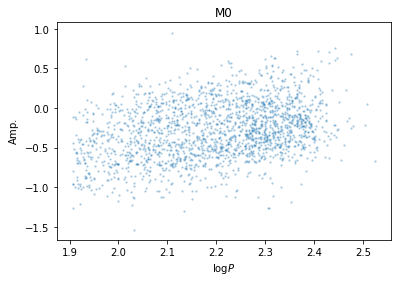

In [19]:
MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
MdotDustIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
JIndex=14 # Column of imported files that has J-band magnitude
HIndex=15 # Column of imported files that has J-band magnitude
KIndex=16 # Column of imported files that has J-band magnitude
ThreePointSixIndex=17 # Column of imported files that has 3.6 band magnitude
FourPointFiveIndex=18 # Column of imported files that has 3.6 band magnitude
FivePointEightIndex=19 # Column of imported files that has 3.6 band magnitude
EightPointZeroIndex=20 # Column of imported files that has 8.0 band magnitude
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data
tauIndex=27 # Column of imported files that has Optical Depth data
AmpIndex=28 # Column of imported files that has pulsation amplitude data



logPData = np.log10(np.transpose(ObservablePlusTable)[PIndex])
AmpData = np.log10(np.transpose(ObservablePlusTable)[AmpIndex])

pyplot.scatter(logPData,AmpData,s=2,alpha=0.25)
pyplot.title('M0')
pyplot.xlabel(r'$\log P$')
pyplot.ylabel(r'$\mathrm{Amp.}$')